# Two markets for the same state price: Kalshi Bitcoin contracts vs the option-implied digital

**Objective:** part of my Graduating Project. A Kalshi contract "Bitcoin above K at 5 pm" pays 1 dollar in one state of the world, so it is a digital option. In the options market the same digital has a price too: under Black-Scholes it is N(d2), and with the Breeden-Litzenberger idea it is the slope of the call prices with respect to the strike. If both markets price the same state, the difference between them (the **wedge**) is the basis risk of a structured note that is hedged in one market and pays in the other.

Here we build a panel of more than 20.000 Kalshi contracts (March 2024 to October 2026) and compare every hourly quote with the digital implied by Bitcoin options:

1. The wedge by moneyness, by time to expiry and by volatility regime
2. The **implied digital volatility**: the volatility that makes N(d2) equal to the Kalshi price, against DVOL and the realised volatility
3. Which price is the better probability: Brier and log scores of Kalshi and of the options digital against what really happened

**Data:**
- Kalshi public API: hourly bid and ask of the KXBTCD markets (5 pm New York), settlement value (CF Benchmarks BRTI)
- Deribit DVOL, the 30-day implied volatility index of Bitcoin options (hourly)
- Binance BTCUSDT hourly close as the spot price

Libraries of the project: `pandas`, `numpy`, `scipy`, `statsmodels`, `matplotlib` and `seaborn`.

## Part 1. Libraries and data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy.stats import norm
from scipy.optimize import brentq

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)

velas = pd.read_parquet("data/kalshi_btc/candles_hourly.parquet")
mercados = pd.read_csv("data/kalshi_btc/markets.csv")
spot = pd.read_parquet("data/kalshi_btc/binance_btcusdt_1h.parquet")[["ts", "close"]].rename(columns={"close": "spot"})
dvol = pd.read_parquet("data/kalshi_btc/deribit_dvol_1h.parquet")
print("Kalshi hourly quotes:", len(velas), "| markets:", velas["ticker"].nunique())
print("Spot hours:", len(spot), "| DVOL hours:", len(dvol))

Kalshi hourly quotes: 493631 | markets: 22612
Spot hours: 23197 | DVOL hours: 24621


## Part 2. The panel

For every market and hour we keep the mid between bid and ask, the spot price of that hour, the DVOL and the hours left to the close. We keep quotes from 1 to 24 hours before the close, with a spread between 0 and 10 cents (a few hourly candles have a bid above the ask, they are not real quotes) and a mid between 2 and 98 cents (outside of that the quote is just the tick).

In [2]:
k = velas.merge(mercados[["ticker", "event_ticker", "strike", "result", "close_time", "expiration_value"]], on="ticker")
k["ts"] = pd.to_datetime(k["ts"], unit="s", utc=True)
k["close_time"] = pd.to_datetime(k["close_time"], utc=True)
k["hours_before"] = ((k["close_time"] - k["ts"]).dt.total_seconds() / 3600).round().astype(int)
k["mid"] = (k["bid"] + k["ask"]) / 2
k["spread"] = k["ask"] - k["bid"]
k["paid"] = (k["result"] == "yes").astype(float)

spot["ts"] = pd.to_datetime(spot["ts"], utc=True)
dvol["ts"] = pd.to_datetime(dvol["ts"], utc=True)
k = k.merge(spot, on="ts").merge(dvol, on="ts")
k = k[(k["hours_before"].between(1, 24)) & (k["spread"].between(0, 0.10)) & (k["mid"].between(0.02, 0.98))].copy()
print("Quotes in the panel:", len(k), "| markets:", k["ticker"].nunique(), "| days:", k["event_ticker"].nunique())
k[["mid", "spread", "spot", "dvol", "hours_before"]].describe().round(3)

Quotes in the panel: 245629 | markets: 19328 | days: 840


,mid,spread,spot,dvol,hours_before
count,245629.000,245629.000,245629.000,245629.000,245629.000
mean,0.502,0.040,85844.378,45.213,12.881
std,0.378,0.026,17876.894,8.014,7.107
min,0.020,0.010,51951.000,32.890,1.000
25%,0.090,0.020,69961.650,38.520,6.000
50%,0.505,0.040,83263.950,43.490,14.000
75%,0.915,0.060,100411.890,51.360,19.000
max,0.980,0.100,126011.180,89.780,24.000


## Part 3. The option-implied digital

With zero interest rate (one day), the price of a digital call that pays 1 if S_T > K is

N(d2), with d2 = [ln(S/K) - sigma^2 tau / 2] / (sigma sqrt(tau))

We use DVOL as sigma. DVOL is a 30-day at-the-money volatility, so it does not have the smile nor the term structure of very short options: part of the wedge is exactly that, and Part 5 measures it with the implied digital volatility.

We also use the **standardised moneyness** z = ln(K/S) / (sigma sqrt(tau)): how many standard deviations the strike is from the spot.

In [3]:
k["tau"] = k["hours_before"] / (24 * 365)
k["sigma"] = k["dvol"] / 100
k["sd"] = k["sigma"] * np.sqrt(k["tau"])
k["z"] = np.log(k["strike"] / k["spot"]) / k["sd"]
k["digital_bs"] = norm.cdf((np.log(k["spot"] / k["strike"]) - k["sd"] ** 2 / 2) / k["sd"])
k["wedge"] = k["mid"] - k["digital_bs"]
print("Mean wedge (Kalshi minus options):", round(k["wedge"].mean(), 4), "| mean absolute wedge:", round(k["wedge"].abs().mean(), 4))
print("Share of quotes where the options digital is inside the Kalshi bid-ask:", round(((k["digital_bs"] >= k["bid"]) & (k["digital_bs"] <= k["ask"])).mean(), 3))

Mean wedge (Kalshi minus options): -0.0003 | mean absolute wedge: 0.0351
Share of quotes where the options digital is inside the Kalshi bid-ask: 0.415


## Part 4. The wedge in the panel

By standardised moneyness (negative z = strike below the spot, the contract is likely to pay) and by hours to the close.

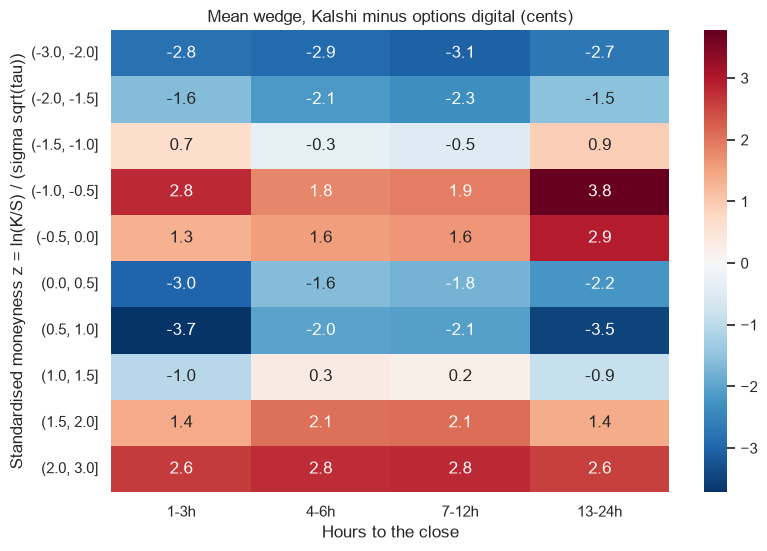

In [4]:
k["z_bin"] = pd.cut(k["z"], [-3, -2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2, 3])
k["h_bin"] = pd.cut(k["hours_before"], [0, 3, 6, 12, 24], labels=["1-3h", "4-6h", "7-12h", "13-24h"])
tabla = k.groupby(["z_bin", "h_bin"], observed=True)["wedge"].mean().unstack() * 100
plt.figure(figsize=(9, 6))
sns.heatmap(tabla, annot=True, fmt=".1f", cmap="RdBu_r", center=0)
plt.title("Mean wedge, Kalshi minus options digital (cents)")
plt.xlabel("Hours to the close")
plt.ylabel("Standardised moneyness z = ln(K/S) / (sigma sqrt(tau))")
plt.savefig("figures/wedge_heatmap.png", bbox_inches="tight")
plt.show()

In [5]:
por_z = k.groupby("z_bin", observed=True).agg(n=("wedge", "size"), kalshi=("mid", "mean"), options=("digital_bs", "mean"),
                                              wedge=("wedge", "mean"), abs_wedge=("wedge", lambda w: w.abs().mean()), half_spread=("spread", lambda s: s.mean() / 2))
por_z.round(3)

,n,kalshi,options,wedge,abs_wedge,half_spread
z_bin,,,,,,
"(-3.0, -2.0]",20107,0.962,0.990,-0.028,0.028,0.017
"(-2.0, -1.5]",18373,0.939,0.957,-0.018,0.025,0.019
"(-1.5, -1.0]",21609,0.894,0.889,0.005,0.037,0.020
"(-1.0, -0.5]",23232,0.800,0.768,0.031,0.053,0.021
"(-0.5, 0.0]",24022,0.618,0.593,0.024,0.038,0.021
"(0.0, 0.5]",23944,0.378,0.399,-0.021,0.038,0.021
"(0.5, 1.0]",23919,0.196,0.226,-0.031,0.053,0.021
"(1.0, 1.5]",22448,0.102,0.107,-0.005,0.036,0.020
"(1.5, 2.0]",18538,0.058,0.042,0.016,0.023,0.019


The wedge has an S shape along the strikes, and it is the same at every horizon:

- **Near the money** (|z| < 1) Kalshi puts more probability on Bitcoin staying close to the spot than N(d2) with DVOL: it pays more for strikes just below the spot and less for strikes just above. The Kalshi distribution is narrower in the centre.
- **In the tails** (|z| > 1.5) it is the opposite: Kalshi pays more for strikes far above the spot and less for strikes far below, so it puts more probability on big moves.

Narrow centre and fat tails: the one-day distribution of Bitcoin is not normal, and one flat 30-day volatility cannot price all the strikes. Part 5 measures it with the implied volatility of each strike.

### The wedge and the volatility regime

We split the days in terciles of DVOL (low, medium and high volatility) and compare the absolute wedge.

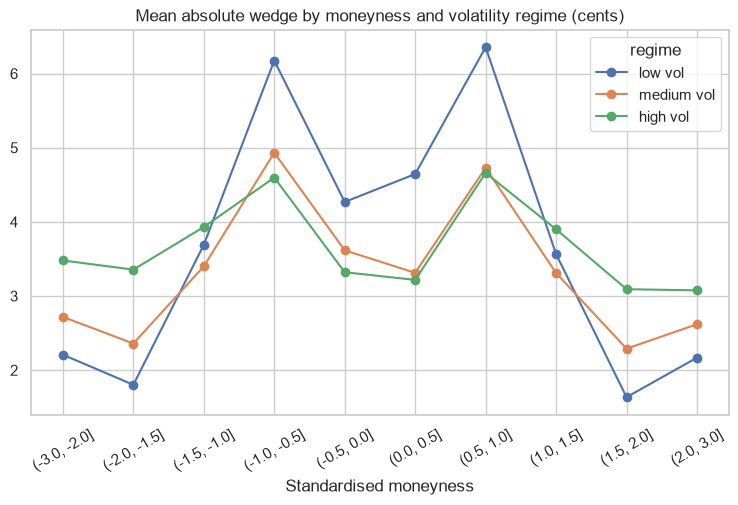

              dvol  abs_wedge  spread
regime                               
low vol     37.258      0.037   0.034
medium vol  43.514      0.033   0.041
high vol    54.887      0.035   0.045


In [6]:
dia = k.groupby("event_ticker")["dvol"].transform("mean")
k["regime"] = pd.qcut(dia, 3, labels=["low vol", "medium vol", "high vol"])
reg = k.groupby(["regime", "z_bin"], observed=True)["wedge"].apply(lambda w: w.abs().mean() * 100).unstack(0)
reg.plot(marker="o", figsize=(9, 5))
plt.title("Mean absolute wedge by moneyness and volatility regime (cents)")
plt.xlabel("Standardised moneyness")
plt.xticks(range(len(reg)), [str(i) for i in reg.index], rotation=30)
plt.savefig("figures/wedge_by_regime.png", bbox_inches="tight")
plt.show()
print(k.groupby("regime", observed=True).agg(dvol=("dvol", "mean"), abs_wedge=("wedge", lambda w: w.abs().mean()), spread=("spread", "mean")).round(3))

A regression of the absolute wedge on the regime, the moneyness, the time to expiry and the spread. Errors clustered by day, because all the strikes of a day move together.

In [7]:
k["abs_wedge"] = k["wedge"].abs() * 100
k["abs_z"] = k["z"].abs()
k["day"] = k["event_ticker"].astype("category").cat.codes
m = smf.ols("abs_wedge ~ C(regime) + abs_z + I(abs_z ** 2) + np.log(hours_before) + I(spread * 100)", k).fit(cov_type="cluster", cov_kwds={"groups": k["day"]})
print(m.summary().tables[1])

                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                   5.1891      0.250     20.748      0.000       4.699       5.679
C(regime)[T.medium vol]    -0.4014      0.214     -1.878      0.060      -0.820       0.018
C(regime)[T.high vol]      -0.1737      0.192     -0.902      0.367      -0.551       0.203
abs_z                      -0.7370      0.061    -12.061      0.000      -0.857      -0.617
I(abs_z ** 2)               0.0415      0.005      8.909      0.000       0.032       0.051
np.log(hours_before)       -0.2499      0.035     -7.154      0.000      -0.318      -0.181
I(spread * 100)             0.0270      0.028      0.980      0.327      -0.027       0.081


## Part 5. The implied digital volatility

For each quote we look for the volatility that makes N(d2) equal to the Kalshi mid. It is the volatility the event market "uses". We only invert quotes with |z| between 0.3 and 2.5: very close to the money the digital price almost does not depend on sigma, and far from it the price is too small.

In [8]:
def vol_digital(p, s, kk, tau):
    f = lambda v: norm.cdf((np.log(s / kk) - v ** 2 * tau / 2) / (v * np.sqrt(tau))) - p
    try:
        return brentq(f, 0.05, 5.0)
    except ValueError:
        return np.nan

inv = k[k["z"].abs().between(0.3, 2.5)].copy()
inv["iv_digital"] = [vol_digital(p, s, kk, t) for p, s, kk, t in zip(inv["mid"], inv["spot"], inv["strike"], inv["tau"])]
inv = inv.dropna(subset=["iv_digital"])
inv["iv_digital"] *= 100
print("Quotes inverted:", len(inv))
inv.groupby(["z_bin"], observed=True)[["iv_digital", "dvol"]].median().round(1)

Quotes inverted: 171477


,iv_digital,dvol
z_bin,,
"(-3.0, -2.0]",54.6,43.8
"(-2.0, -1.5]",47.0,42.9
"(-1.5, -1.0]",42.0,42.7
"(-1.0, -0.5]",39.0,42.7
"(-0.5, 0.0]",37.8,42.7
"(0.0, 0.5]",37.6,42.6
"(0.5, 1.0]",38.6,42.7
"(1.0, 1.5]",41.9,42.8
"(1.5, 2.0]",47.1,43.2


Near the money the volatility implied by Kalshi is around 38%, below the 43% of DVOL, and in the tails it goes up to 55%: it is a smile, like the one of short-term options. The implied digital volatility of each day (median of its quotes 6 to 12 hours before the close) against DVOL and against the realised volatility of that day (hourly returns of Binance in the 24 hours to the close).

       iv_digital   dvol  realised
count       821.0  821.0     821.0
mean         50.5   47.2      41.6
std          18.8    9.3      21.5
min          14.7   34.0       6.4
25%          38.0   38.8      26.6
50%          48.8   46.0      39.5
75%          61.5   54.6      51.1
max         130.6   77.7     193.1
            iv_digital   dvol  realised
iv_digital       1.000  0.766     0.780
dvol             0.766  1.000     0.515
realised         0.780  0.515     1.000


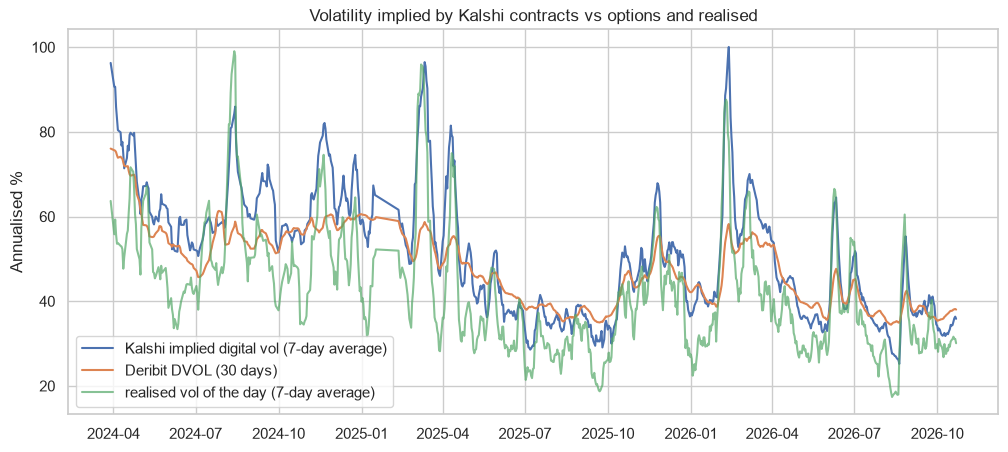

In [9]:
spot_s = spot.set_index("ts")["spot"]
r_h = np.log(spot_s).diff()
diario = inv[inv["hours_before"].between(6, 12)].groupby("event_ticker").agg(close_time=("close_time", "first"), iv_digital=("iv_digital", "median"), dvol=("dvol", "mean"))
diario["realised"] = [np.sqrt((r_h[(r_h.index > c - pd.Timedelta(hours=24)) & (r_h.index <= c)] ** 2).sum() * 365) * 100 for c in diario["close_time"]]
diario = diario.sort_values("close_time").set_index("close_time")
print(diario[["iv_digital", "dvol", "realised"]].describe().round(1))
print(diario[["iv_digital", "dvol", "realised"]].corr().round(3))

plt.figure(figsize=(12, 5))
plt.plot(diario.index, diario["iv_digital"].rolling(7).mean(), label="Kalshi implied digital vol (7-day average)")
plt.plot(diario.index, diario["dvol"].rolling(7).mean(), label="Deribit DVOL (30 days)")
plt.plot(diario.index, diario["realised"].rolling(7).mean(), label="realised vol of the day (7-day average)", alpha=0.7)
plt.title("Volatility implied by Kalshi contracts vs options and realised")
plt.ylabel("Annualised %")
plt.legend()
plt.savefig("figures/implied_digital_vol.png", bbox_inches="tight")
plt.show()

Is the implied digital volatility a better forecast of the realised volatility than DVOL? A Mincer-Zarnowitz regression: realised = a + b * forecast. A good forecast has b close to 1 and a high R-squared.

In [10]:
for x in ["iv_digital", "dvol"]:
    mz = smf.ols(f"realised ~ {x}", diario).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    print(x, "| b:", round(mz.params[x], 3), "| R2:", round(mz.rsquared, 3))
mz2 = smf.ols("realised ~ iv_digital + dvol", diario).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
print(mz2.params.round(3), "| R2 both:", round(mz2.rsquared, 3))

iv_digital | b: 0.893 | R2: 0.609
dvol | b: 1.195 | R2: 0.266
Intercept     9.434
iv_digital    1.067
dvol         -0.459
dtype: float64 | R2 both: 0.625


## Part 6. Which price is the better probability?

The outcome of every contract is known, so we can score both prices as forecasts. We add a third one: N(d2) with the **trailing** realised volatility of the last 24 hours instead of DVOL.

In [11]:
r24 = np.sqrt((r_h ** 2).rolling(24).sum() * 365)
k["rv24"] = k["ts"].map(r24)
k["digital_rv"] = norm.cdf((np.log(k["spot"] / k["strike"]) - k["rv24"] ** 2 * k["tau"] / 2) / (k["rv24"] * np.sqrt(k["tau"])))

def scores(q, y):
    q = np.clip(q, 0.001, 0.999)
    return pd.Series({"brier": np.mean((q - y) ** 2), "log_score": -np.mean(y * np.log(q) + (1 - y) * np.log(1 - q))})

res = []
for h in [1, 3, 6, 12, 24]:
    x = k[(k["hours_before"] == h)].dropna(subset=["digital_rv"])
    for nombre, col in [("Kalshi mid", "mid"), ("options N(d2), DVOL", "digital_bs"), ("N(d2), realised vol 24h", "digital_rv")]:
        res.append({"hours_before": h, "forecast": nombre, "n": len(x), **scores(x[col].values, x["paid"].values)})
res = pd.DataFrame(res)
res.pivot(index="hours_before", columns="forecast", values="brier").round(4)

forecast,Kalshi mid,"N(d2), realised vol 24h","options N(d2), DVOL"
hours_before,,,
1,0.0384,0.0375,0.0389
3,0.0572,0.0572,0.0588
6,0.0726,0.0725,0.0737
12,0.1047,0.1090,0.1084
24,0.1069,0.1109,0.1101


Calibration of the three at 6 hours before the close.

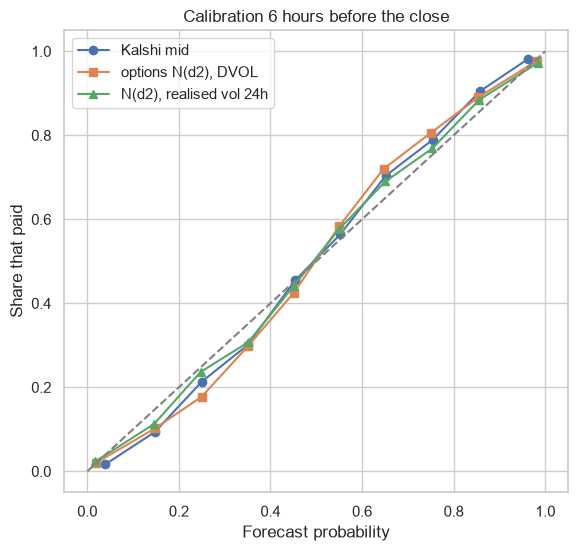

In [12]:
x = k[k["hours_before"] == 6].dropna(subset=["digital_rv"])
plt.figure(figsize=(6.5, 6))
for nombre, col, mk in [("Kalshi mid", "mid", "o"), ("options N(d2), DVOL", "digital_bs", "s"), ("N(d2), realised vol 24h", "digital_rv", "^")]:
    b = pd.cut(x[col], np.linspace(0, 1, 11))
    c = x.groupby(b, observed=True).agg(p=(col, "mean"), f=("paid", "mean"))
    plt.plot(c["p"], c["f"], marker=mk, label=nombre)
plt.plot([0, 1], [0, 1], ls="--", color="grey")
plt.title("Calibration 6 hours before the close")
plt.xlabel("Forecast probability")
plt.ylabel("Share that paid")
plt.legend()
plt.savefig("figures/calibration_three_prices.png", bbox_inches="tight")
plt.show()

## Part 7. The wedge in dollars: basis risk of a note

Suppose a note promises a digital coupon of 1.000 dollars if Bitcoin closes above K tomorrow at 5 pm, and the bank hedges it with options priced with DVOL but the investor could buy the same payoff on Kalshi. The wedge is the price difference for the same promise. The distribution of the wedge for contracts near the money (|z| < 1) 6 hours before the close:

count    3707.0
mean       -0.7
std        58.9
min      -252.9
5%       -102.1
25%       -28.6
50%        -1.1
75%        26.4
95%       103.6
max       235.4
Name: wedge, dtype: float64


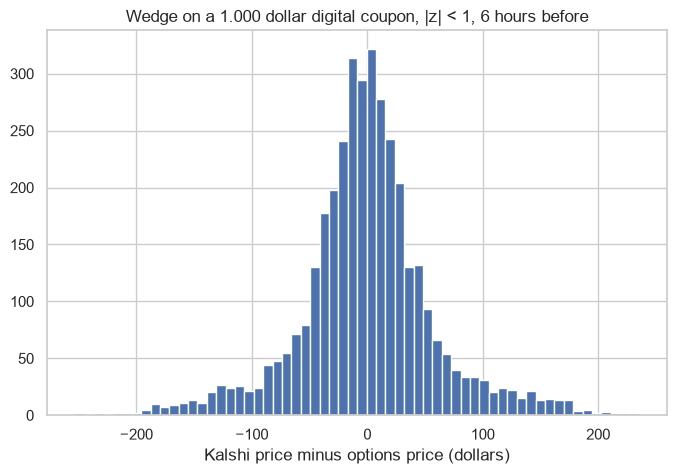

In [13]:
cerca = k[(k["z"].abs() < 1) & (k["hours_before"] == 6)]
dist = (cerca["wedge"] * 1000).describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])
print(dist.round(1))
plt.figure(figsize=(8, 5))
plt.hist(cerca["wedge"] * 1000, bins=60)
plt.title("Wedge on a 1.000 dollar digital coupon, |z| < 1, 6 hours before")
plt.xlabel("Kalshi price minus options price (dollars)")
plt.savefig("figures/wedge_dollars.png", bbox_inches="tight")
plt.show()

## Conclusions

- **The two markets agree on average but not strike by strike.** In 245.000 hourly quotes (840 days) the mean wedge between Kalshi and N(d2) with DVOL is zero, but the mean absolute wedge is 3.5 cents, larger than the half spread of Kalshi (around 2 cents), and the options digital is inside the Kalshi bid-ask only in 41% of the quotes.
- **The wedge has a shape:** Kalshi gives more probability to small moves (narrow centre) and to big moves (fat tails) than a normal with the 30-day volatility. The implied volatility of the Kalshi ladder is a smile: 38% near the money and 55% in the tails, with DVOL at 43%. The wedge is larger close to the expiry, and it is not larger in the high volatility regime once moneyness and time are controlled.
- **Kalshi knows more about tomorrow's volatility than DVOL.** The daily implied digital volatility explains 61% of the variance of the realised volatility of the next day, against 27% for DVOL (a 30-day index), and with both in the regression DVOL adds nothing.
- **As a forecast, the Kalshi price is at least as good as the options digital:** its Brier score is lower than N(d2) with DVOL at every horizon from 1 to 24 hours, and lower than N(d2) with the realised volatility of the last 24 hours at 12 and 24 hours.
- **Basis risk in dollars:** for a digital coupon of 1.000 dollars near the money, 6 hours before the close, the price in the two markets differs by 59 dollars (standard deviation), and in 10% of the days by more than 100 dollars. This is the price basis that the twin notes notebook carries into the P&L of the issuer.